<a href="https://colab.research.google.com/github/marialabadi/big-data/blob/main/TP2_Big_Data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip -q install pandas "dask[complete]" psutil matplotlib pyarrow requests graphviz
!apt-get -qq install -y graphviz > /dev/null

In [2]:
import os, sys, time, threading
import multiprocessing as mp
import numpy as np
import pandas as pd
import psutil
import matplotlib.pyplot as plt

DATA_DIR = "/content/data"                          # مجلد البيانات
CSV_PATH = os.path.join(DATA_DIR, "big_taxi.csv")   # الملف الكبير النهائي
TARGET_SIZE_GB = 5.5                                # الحجم المطلوب (أكبر من 5GB)
CHUNK_SIZE = 100_000                                # حجم القطعة حسب التمرين
DATA_SOURCE = "real"                                # "real" = NYC Taxi حقيقية | "synthetic" = اصطناعية

COLUMNS = [
    "VendorID", "tpep_pickup_datetime", "tpep_dropoff_datetime",
    "passenger_count", "trip_distance", "PULocationID", "DOLocationID",
    "payment_type", "fare_amount", "tip_amount", "total_amount",
]

os.makedirs(DATA_DIR, exist_ok=True)

def file_size_gb(path):
    """حجم الملف بالجيغابايت."""
    return os.path.getsize(path) / 1024 ** 3 if os.path.exists(path) else 0.0

In [3]:
TLC_URL = "https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_{ym}.parquet"

def build_real_dataset():
    """تحميل أشهر NYC Taxi وتحويلها إلى CSV واحد حتى الوصول للحجم المطلوب."""
    import requests
    import pyarrow.parquet as pq

    if file_size_gb(CSV_PATH) >= TARGET_SIZE_GB:
        print(f"الملف موجود مسبقاً: {file_size_gb(CSV_PATH):.2f} GB")
        return

    if os.path.exists(CSV_PATH):
        os.remove(CSV_PATH)
    first = True
    months = [f"{y}-{m:02d}" for y in range(2019, 2024) for m in range(1, 13)]
    for ym in months:
        if file_size_gb(CSV_PATH) >= TARGET_SIZE_GB:
            break
        pq_path = os.path.join(DATA_DIR, f"yellow_{ym}.parquet")
        print(f"تحميل {ym} ...")
        try:
            with requests.get(TLC_URL.format(ym=ym), stream=True, timeout=60) as r:
                r.raise_for_status()
                with open(pq_path, "wb") as f:
                    for part in r.iter_content(chunk_size=1024 * 1024):
                        f.write(part)
        except Exception as e:
            print(f"  فشل تحميل {ym}: {e}")
            continue

        df = pq.read_table(pq_path, columns=[c for c in COLUMNS if c != "VendorID"]
                           + ["VendorID"]).to_pandas()
        df = df[COLUMNS]
        df["passenger_count"] = df["passenger_count"].fillna(1).astype("int8")
        df["payment_type"] = df["payment_type"].fillna(0).astype("int8")
        df.to_csv(CSV_PATH, mode="a", header=first, index=False)
        first = False
        del df
        os.remove(pq_path)
        print(f"  الحجم الحالي: {file_size_gb(CSV_PATH):.2f} GB")

    print(f"انتهى. الحجم النهائي: {file_size_gb(CSV_PATH):.2f} GB")


def build_synthetic_dataset(seed=42):
    """توليد بيانات اصطناعية بنفس بنية NYC Taxi (بدون إنترنت)."""
    rng = np.random.default_rng(seed)
    if os.path.exists(CSV_PATH):
        os.remove(CSV_PATH)
    first = True
    n = 2_000_000
    start = pd.Timestamp("2022-01-01").value // 10 ** 9
    while file_size_gb(CSV_PATH) < TARGET_SIZE_GB:
        pickup = pd.to_datetime(rng.integers(start, start + 365 * 86400, n), unit="s")
        dist = np.round(rng.gamma(2.0, 1.6, n), 2)
        fare = np.round(2.5 + dist * 2.7 + rng.normal(0, 1.5, n).clip(-2), 2)
        tip = np.round(fare * rng.choice([0, 0.1, 0.15, 0.2], n), 2)
        df = pd.DataFrame({
            "VendorID": rng.integers(1, 3, n).astype("int8"),
            "tpep_pickup_datetime": pickup,
            "tpep_dropoff_datetime": pickup + pd.to_timedelta(dist * 4 + 3, unit="m"),
            "passenger_count": rng.integers(1, 7, n).astype("int8"),
            "trip_distance": dist,
            "PULocationID": rng.integers(1, 264, n).astype("int16"),
            "DOLocationID": rng.integers(1, 264, n).astype("int16"),
            "payment_type": rng.integers(1, 5, n).astype("int8"),
            "fare_amount": fare,
            "tip_amount": tip,
            "total_amount": np.round(fare + tip + 0.5 + 0.8, 2),
        })
        df.to_csv(CSV_PATH, mode="a", header=first, index=False)
        first = False
        print(f"الحجم الحالي: {file_size_gb(CSV_PATH):.2f} GB")
    print(f"انتهى التوليد: {file_size_gb(CSV_PATH):.2f} GB")


def prepare_data():
    if DATA_SOURCE == "real":
        build_real_dataset()
        if file_size_gb(CSV_PATH) < 5:
            print("الحجم أقل من 5GB، سيتم استكماله بالتوليد الاصطناعي.")
            build_synthetic_dataset()
    else:
        build_synthetic_dataset()

In [4]:
class MemoryMonitor:
    """خيط يراقب ذاكرة العملية كل 0.1 ثانية ويحفظ أعلى قيمة."""
    def __init__(self, interval=0.1):
        self.interval = interval
        self.peak = 0
        self._stop = threading.Event()
        self._proc = psutil.Process(os.getpid())

    def _run(self):
        while not self._stop.is_set():
            try:
                rss = self._proc.memory_info().rss
                for ch in self._proc.children(recursive=True):
                    rss += ch.memory_info().rss
                self.peak = max(self.peak, rss)
            except psutil.Error:
                pass
            time.sleep(self.interval)

    def __enter__(self):
        self._t = threading.Thread(target=self._run, daemon=True)
        self._t.start()
        return self

    def __exit__(self, *a):
        self._stop.set()
        self._t.join()

    @property
    def peak_gb(self):
        return self.peak / 1024 ** 3


TOTAL_RAM_GB = psutil.virtual_memory().total / 1024 ** 3
results = {}

In [5]:
TASK1_MEM_LIMIT_GB = 4   # سقف الذاكرة للعملية الفرعية

def _task1_worker(q, path, limit_gb):
    try:
        import resource
        if limit_gb:
            lim = int(limit_gb * 1024 ** 3)
            resource.setrlimit(resource.RLIMIT_AS, (lim, lim))
    except ImportError:
        pass

    t0 = time.time()
    try:
        with MemoryMonitor() as mon:
            df = pd.read_csv(path)            # المحاولة التقليدية
            _ = df["total_amount"].mean()
        q.put(("OK", time.time() - t0, mon.peak_gb, ""))
    except MemoryError as e:
        q.put(("MemoryError", time.time() - t0, mon.peak_gb, str(e)))
    except Exception as e:
        q.put((type(e).__name__, time.time() - t0, 0, str(e)))


def task1_standard_pandas():
    print("=" * 60)
    print(f"Task 1: pd.read_csv على ملف حجمه {file_size_gb(CSV_PATH):.2f} GB")
    print(f"الرام الكلية في جهازك: {TOTAL_RAM_GB:.1f} GB")
    q = mp.Queue()
    p = mp.Process(target=_task1_worker, args=(q, CSV_PATH, TASK1_MEM_LIMIT_GB))
    t0 = time.time()
    p.start()
    p.join()
    elapsed = time.time() - t0

    if not q.empty():
        status, t, peak, msg = q.get()
    else:
        status, t, peak, msg = f"Killed (exit {p.exitcode})", elapsed, TOTAL_RAM_GB, ""

    print(f"الحالة: {status} | الزمن: {t:.1f}s | أعلى رام: {peak:.2f} GB")
    if status != "OK":
        print("-> تم توثيق الفشل (هذا هو المطلوب في Task 1). خذ لقطة شاشة.")
    results["Standard Pandas"] = {"status": status,
                                  "time": None if status != "OK" else t,
                                  "peak_gb": peak}

In [6]:
def task2_pandas_chunking():
    print("=" * 60)
    print(f"Task 2: Chunking بحجم {CHUNK_SIZE:,} سطر")

    total_sum = 0.0
    total_count = 0
    max_dist = 0.0
    per_zone = {}
    n_chunks = 0

    t0 = time.time()
    with MemoryMonitor() as mon:
        for chunk in pd.read_csv(CSV_PATH,
                                 usecols=["PULocationID", "trip_distance", "total_amount"],
                                 chunksize=CHUNK_SIZE):
            n_chunks += 1
            amount = chunk["total_amount"]
            total_sum += amount.sum()
            total_count += amount.count()
            max_dist = max(max_dist, chunk["trip_distance"].max())

            g = chunk.groupby("PULocationID")["total_amount"].agg(["sum", "count"])
            for zone, row in g.iterrows():
                acc = per_zone.setdefault(zone, [0.0, 0])
                acc[0] += row["sum"]
                acc[1] += row["count"]

            if n_chunks % 50 == 0:
                print(f"  عولجت {n_chunks * CHUNK_SIZE:,} سطر ...")
    elapsed = time.time() - t0

    print(f"عدد القطع: {n_chunks} | عدد الأسطر: {total_count:,}")
    print(f"المجموع العام: {total_sum:,.2f}")
    print(f"المتوسط العام لـ total_amount: {total_sum / total_count:.4f}")
    print(f"أكبر مسافة رحلة: {max_dist}")
    print(f"الزمن: {elapsed:.1f}s | أعلى رام: {mon.peak_gb:.2f} GB")

    top = sorted(per_zone.items(), key=lambda kv: kv[1][0] / kv[1][1], reverse=True)[:5]
    print("أعلى 5 مناطق بمتوسط الأجرة:", [(z, round(s / c, 2)) for z, (s, c) in top])
    results["Pandas Chunking"] = {"status": "OK", "time": elapsed, "peak_gb": mon.peak_gb,
                                  "mean": total_sum / total_count, "rows": total_count}

In [7]:
def task3_dask():
    import dask
    import dask.dataframe as dd
    from dask.diagnostics import ProgressBar

    print("=" * 60)
    print("Task 3: Dask DataFrame")

    # التحميل كسول (Lazy): لا يُقرأ الملف الآن، بل يُبنى مخطط مهام فقط
    ddf = dd.read_csv(
        CSV_PATH,
        usecols=["PULocationID", "trip_distance", "payment_type", "total_amount"],
        dtype={"PULocationID": "int32", "trip_distance": "float32",
               "payment_type": "int8", "total_amount": "float32"},
        blocksize="128MB",
    )
    print(f"عدد الـ partitions: {ddf.npartitions}")
    print("لاحظ: لم يُقرأ الملف بعد (Lazy) ->", type(ddf))

    # عمليات كسولة
    mean_amount = ddf["total_amount"].mean()
    sum_amount = ddf["total_amount"].sum()
    rows = ddf["total_amount"].count()
    zone_mean = ddf.groupby("PULocationID")["total_amount"].mean()

    # مقارنة المخطط قبل وبعد التحسين
    try:
        graph_raw = dict(dask.base.collections_to_dsk(
            [mean_amount, sum_amount, rows, zone_mean], optimize_graph=False))
        (opt_mean, opt_sum, opt_rows, opt_zone) = dask.optimize(
            mean_amount, sum_amount, rows, zone_mean)
        graph_opt = dict(opt_mean.__dask_graph__())
        print(f"عقد المخطط قبل التحسين: {len(graph_raw)}")
        print(f"عقد المخطط بعد التحسين: {len(graph_opt)}")
    except Exception as e:
        print(f"تعذر عدّ عقد المخطط في هذا الإصدار من dask: {e}")
        (opt_mean, opt_sum, opt_rows, opt_zone) = (mean_amount, sum_amount, rows, zone_mean)

    # رسم المخطط
    try:
        mean_amount.visualize(filename=os.path.join(DATA_DIR, "dask_graph_raw.png"),
                              optimize_graph=False)
        mean_amount.visualize(filename=os.path.join(DATA_DIR, "dask_graph_opt.png"),
                              optimize_graph=True)
        print("تم حفظ رسمي المخطط في مجلد data.")
    except Exception as e:
        print(f"تعذر رسم المخطط: {e}")

    # التنفيذ الفعلي: compute واحد لكل النتائج
    t0 = time.time()
    with MemoryMonitor() as mon, ProgressBar():
        m, s, r, z = dask.compute(opt_mean, opt_sum, opt_rows, opt_zone,
                                  scheduler="threads")
    elapsed = time.time() - t0

    print(f"عدد الأسطر: {int(r):,}")
    print(f"المجموع العام: {float(s):,.2f}")
    print(f"المتوسط العام لـ total_amount: {float(m):.4f}")
    print(f"أعلى 5 مناطق: {z.sort_values(ascending=False).head(5).round(2).to_dict()}")
    print(f"الزمن: {elapsed:.1f}s | أعلى رام: {mon.peak_gb:.2f} GB")
    results["Dask DataFrame"] = {"status": "OK", "time": elapsed, "peak_gb": mon.peak_gb,
                                 "mean": float(m), "rows": int(r)}

In [8]:
def final_comparison():
    print("=" * 60)
    rows = []
    for method, r in results.items():
        rows.append({
            "Method": method,
            "Status": r["status"],
            "Max RAM (GB)": round(r["peak_gb"], 2),
            "Max RAM (% of total)": round(100 * r["peak_gb"] / TOTAL_RAM_GB, 1),
            "Time (s)": "N/A" if r["time"] is None else round(r["time"], 1),
        })
    table = pd.DataFrame(rows)
    print(table.to_string(index=False))
    table.to_csv(os.path.join(DATA_DIR, "benchmark_results.csv"), index=False)

    ok = {k: v for k, v in results.items() if v["time"] is not None}
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].bar(results.keys(), [v["peak_gb"] for v in results.values()],
              color=["#c0392b", "#f39c12", "#27ae60"][:len(results)])
    ax[0].set_title("Peak RAM (GB)")
    ax[0].set_ylabel("GB")
    ax[1].bar(ok.keys(), [v["time"] for v in ok.values()],
              color=["#f39c12", "#27ae60"][-len(ok):])
    ax[1].set_title("Execution Time (s)")
    ax[1].set_ylabel("seconds")
    for a in ax:
        a.tick_params(axis="x", rotation=15)
    plt.tight_layout()
    out = os.path.join(DATA_DIR, "benchmark.png")
    plt.savefig(out, dpi=150)
    print(f"تم حفظ الرسم: {out}")
    plt.show()

    if "Pandas Chunking" in results and "Dask DataFrame" in results:
        a, b = results["Pandas Chunking"]["mean"], results["Dask DataFrame"]["mean"]
        print(f"فرق المتوسط بين الطريقتين: {abs(a - b):.6f} (يجب أن يكون ~0)")

In [9]:
prepare_data()
print(f'حجم الملف: {file_size_gb(CSV_PATH):.2f} GB')
!ls -lh /content/data

تحميل 2019-01 ...
  الحجم الحالي: 0.52 GB
تحميل 2019-02 ...
  الحجم الحالي: 0.99 GB
تحميل 2019-03 ...
  الحجم الحالي: 1.53 GB
تحميل 2019-04 ...
  الحجم الحالي: 2.03 GB
تحميل 2019-05 ...
  الحجم الحالي: 2.55 GB
تحميل 2019-06 ...
  الحجم الحالي: 3.02 GB
تحميل 2019-07 ...
  الحجم الحالي: 3.44 GB
تحميل 2019-08 ...
  الحجم الحالي: 3.85 GB
تحميل 2019-09 ...
  الحجم الحالي: 4.30 GB
تحميل 2019-10 ...
  الحجم الحالي: 4.79 GB
تحميل 2019-11 ...
  الحجم الحالي: 5.25 GB
تحميل 2019-12 ...
  الحجم الحالي: 5.72 GB
انتهى. الحجم النهائي: 5.72 GB
حجم الملف: 5.72 GB
total 5.8G
-rw-r--r-- 1 root root 5.8G Oct 13 21:44 big_taxi.csv


In [10]:
task1_standard_pandas()

Task 1: pd.read_csv على ملف حجمه 5.72 GB
الرام الكلية في جهازك: 12.7 GB
الحالة: MemoryError | الزمن: 21.7s | أعلى رام: 1.94 GB
-> تم توثيق الفشل (هذا هو المطلوب في Task 1). خذ لقطة شاشة.


In [11]:
task2_pandas_chunking()

Task 2: Chunking بحجم 100,000 سطر
  عولجت 5,000,000 سطر ...
  عولجت 10,000,000 سطر ...
  عولجت 15,000,000 سطر ...
  عولجت 20,000,000 سطر ...
  عولجت 25,000,000 سطر ...
  عولجت 30,000,000 سطر ...
  عولجت 35,000,000 سطر ...
  عولجت 40,000,000 سطر ...
  عولجت 45,000,000 سطر ...
  عولجت 50,000,000 سطر ...
  عولجت 55,000,000 سطر ...
  عولجت 60,000,000 سطر ...
  عولجت 65,000,000 سطر ...
  عولجت 70,000,000 سطر ...
  عولجت 75,000,000 سطر ...
  عولجت 80,000,000 سطر ...
عدد القطع: 846 | عدد الأسطر: 84,598,444
المجموع العام: 1,623,638,298.64
المتوسط العام لـ total_amount: 19.1923
أكبر مسافة رحلة: 45977.22
الزمن: 96.9s | أعلى رام: 0.44 GB
أعلى 5 مناطق بمتوسط الأجرة: [(1, np.float64(96.74)), (5, np.float64(82.04)), (265, np.float64(81.48)), (204, np.float64(77.84)), (23, np.float64(74.64))]


In [12]:
task3_dask()

Task 3: Dask DataFrame
عدد الـ partitions: 47
لاحظ: لم يُقرأ الملف بعد (Lazy) -> <class 'dask.dataframe.dask_expr._collection.DataFrame'>
تعذر عدّ عقد المخطط في هذا الإصدار من dask: module 'dask.base' has no attribute 'collections_to_dsk'
تعذر رسم المخطط: expected string or bytes-like object, got 'bool'
[########################################] | 100% Completed | 93.72 s
عدد الأسطر: 84,598,444
المجموع العام: 1,623,638,144.00
المتوسط العام لـ total_amount: 19.1923
أعلى 5 مناطق: {1: 96.74, 5: 82.04, 265: 81.48, 204: 77.84, 23: 74.64}
الزمن: 94.8s | أعلى رام: 1.32 GB


         Method      Status  Max RAM (GB)  Max RAM (% of total) Time (s)
Standard Pandas MemoryError          1.94                  15.3      N/A
Pandas Chunking          OK          0.44                   3.5     96.9
 Dask DataFrame          OK          1.32                  10.4     94.8
تم حفظ الرسم: /content/data/benchmark.png


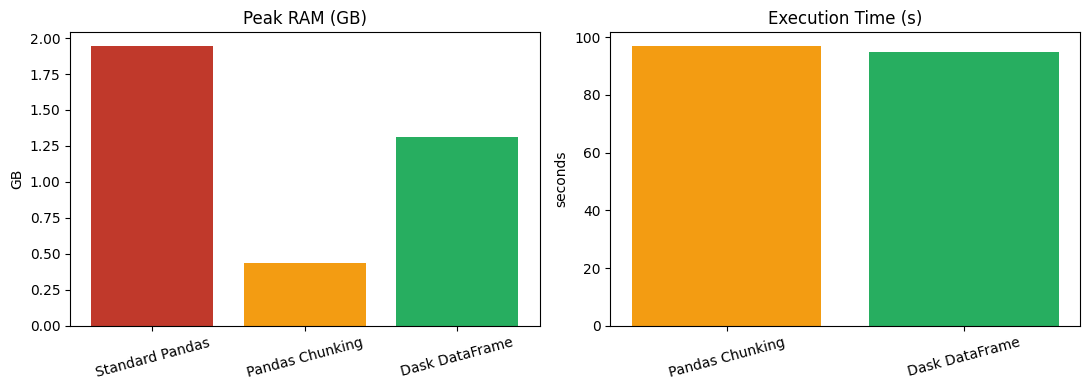

فرق المتوسط بين الطريقتين: 0.000002 (يجب أن يكون ~0)


In [13]:
final_comparison()

In [14]:
from google.colab import files
files.download('/content/data/benchmark_results.csv')
files.download('/content/data/benchmark.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>